# LateGraph — milestone notebook

**CS 224W project (Yijin Li, Lexi Zhou).** Memory-based temporal GNNs such as TGN keep one memory vector per node and
update it at every event. Real event logs change after the fact: events arrive **late**, get **amended**, or must be
**deleted**. One edit to the past changes every later memory update that read an affected memory — the edit's
*dependency cone*. This notebook shows the pieces we built in PyG:

1. a stream with **two clocks** (when an event happened, when we found out),
2. `RetroactiveTGNMemory`, a subclass of PyG's `TGNMemory` that can insert, delete and amend past events and
   **repair its memory exactly** (only the cone is recomputed) or approximately (ε-repair),
3. a **streaming evaluation** that compares repair policies under late arrivals,
4. a **membership test** showing that deleting an event from the log alone does not delete it from the memory.

Runtime: about 10 minutes on a Colab CPU (no GPU needed).

## 1. Setup
Install PyG and get the code. On Colab we clone the repository; locally, point `CODE_DIR` at the repo.

In [1]:
import os, sys, subprocess
REPO_URL = "https://github.com/YOUR-ACCOUNT/lategraph"      # <- the public repository with this code
CODE_DIR = os.environ.get("LATEGRAPH_CODE", "/content/lategraph")
if "google.colab" in sys.modules:
    subprocess.run("pip -q install torch_geometric scikit-learn", shell=True)
    if not os.path.exists(CODE_DIR):
        subprocess.run(f"git clone -q {REPO_URL} {CODE_DIR}", shell=True)
    os.environ.setdefault("LATEGRAPH_HOME", "/content/lategraph_home")
sys.path.insert(0, CODE_DIR)
import numpy as np, torch, matplotlib.pyplot as plt
torch.set_num_threads(2); torch.manual_seed(0)
print(torch.__version__)

2.14.1


## 2. Data: Wikipedia from PyG's `JODIEDataset`
157,474 edits of 1,000 pages by 8,227 users, each with a 172-dim text feature vector. We split by time
(70% train, 15% validation, 15% test), exactly like `TemporalData.train_val_test_split`.

In [2]:
from lategraph.data import load_jodie
S = load_jodie("wikipedia")          # downloads ~560 MB the first time
S.summary()

{'name': 'wikipedia', 'events': 157474, 'nodes': 9227, 'src_nodes': 8227, 'dst_nodes': 1000, 'msg_dim': 172, 'train': 110232, 'val': 23621, 'test': 23621, 'span_days': 30.9996875}

## 3. Train a small TGN
The model is PyG's TGN as in `examples/tgn.py`: `TGNMemory` (GRU memory, last-message aggregation), a
`TransformerConv` embedding over each node's last 10 neighbours, and an MLP link decoder. We train for 3 epochs here
(the paper runs use 15 epochs and 3 seeds).

In [3]:
from lategraph.model import TGNConfig
from lategraph.train import train_tgn
model, info = train_tgn(S, TGNConfig(), epochs=3, seed=0, threads=2)
print("best validation AP:", round(info["best_val_ap"], 4))

wikipedia seed 0 ep 01 loss 1.1099 val AP 0.8586 (8s)
wikipedia seed 0 ep 02 loss 0.8089 val AP 0.9137 (9s)
wikipedia seed 0 ep 03 loss 0.7266 val AP 0.9363 (8s)
best validation AP: 0.9363


## 4. The second clock: simulated arrival times
JODIE only records when an interaction happened. We make 20% of test events late, with a log-normal delay
(median 2 hours). The test stream is processed in steps of 200 events; an event can only be used once it has arrived.

{'J': 40, 'test_events': 8000, 'late_frac': 0.19349999725818634, 'never_received': 380, 'late_steps_median': 2.0, 'late_steps_p90': 8.0, 'late_steps_max': 35, 'queries': 8000}


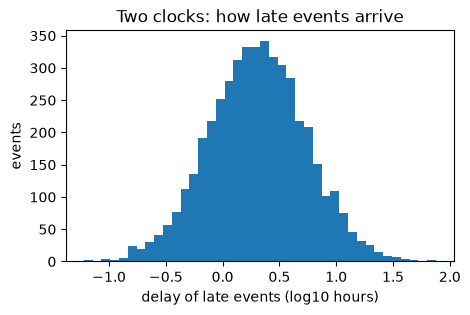

In [4]:
from lategraph.delays import make_delays, arrival_times
from lategraph.stream import make_setup
delay = make_delays(S, "rand", seed=0, p=0.2, med=2.0)
arrival = arrival_times(S, delay)
setup = make_setup(S, arrival, bq=200, max_steps=40)
print(setup.info)
late = delay[delay > 0] / 3600
plt.figure(figsize=(5, 3)); plt.hist(np.log10(late), bins=40)
plt.xlabel("delay of late events (log10 hours)"); plt.ylabel("events"); plt.title("Two clocks: how late events arrive"); plt.show()

## 5. `RetroactiveTGNMemory`: change the past, repair the memory
We process 40 test steps, then insert one event into step 5 as if it had just arrived (35 steps late). `repair("exact")` rolls the
memory back with its journal and recomputes only the dependency cone; `repair("replay")` recomputes everything after
step 5. Both must give the same memory.

In [5]:
from lategraph.memory import RetroactiveTGNMemory
from lategraph.stream import warm_start
mem, store = warm_start(model, S, setup.table)
# pick an event that is the latest one of both its endpoints in step 5 (otherwise TGN's last-message aggregation
# ignores it and the cone is empty -- which the repair also detects)
b5 = setup.batches[5]
later = lambda i: torch.cat([S.src[b5[i + 1:]], S.dst[b5[i + 1:]]])
i = next(i for i in range(b5.numel()) if not bool(torch.isin(torch.stack([S.src[b5[i]], S.dst[b5[i]]]), later(i)).any()))
late_event = b5[i:i + 1]                                   # pretend this event was missing so far
for k in range(40):
    ev = setup.batches[k]
    mem.advance(ev[~torch.isin(ev, late_event)])
a = RetroactiveTGNMemory.from_trained(model.memory, setup.table).copy_state_from(mem)
b = RetroactiveTGNMemory.from_trained(model.memory, setup.table).copy_state_from(mem)
a.edit(insert=late_event); st_a = a.repair("exact")
b.edit(insert=late_event); st_b = b.repair("replay")
print(f"exact repair recomputed {st_a.recomputed} updates, full replay {st_b.recomputed} "
      f"(window has {st_a.window_updates} updates)")
print("max |exact - replay| =", float((a.memory - b.memory).abs().max()))
print("memories changed by the late event:", st_a.changed_nodes)

exact repair recomputed 10 updates, full replay 5162 (window has 5160 updates)
max |exact - replay| = 0.0
memories changed by the late event: 3


## 6. Streaming evaluation of repair policies
Every policy sees the same received events and the same negatives; only the memory handling differs.
`oracle` gets every event on time; `exact` inserts late events into the past and repairs the cone; `eps:0.05` stops
where the change is below 5%; `arrival` applies late events when they arrive; `buffer:1` waits one hour.

In [6]:
from lategraph.stream import Policy, evaluate_stream, sample_negatives
negs_r, negs_h = sample_negatives(S, setup, seed=1234)
policies = [Policy(m, model, setup, mem0, store0) for (mem0, store0) in [warm_start(model, S, setup.table)]
            for m in ["oracle", "exact", "replay", "eps:0.05", "arrival", "buffer:1"]]
summary, arrays = evaluate_stream(model, setup, policies, negs_r, negs_h, ref="exact", log=None)
import pandas as pd
pd.DataFrame(summary["methods"]).T[["mrr", "mrr_hist", "cost_x_normal", "top1_agree", "sec"]].round(4)

,mrr,mrr_hist,cost_x_normal,top1_agree,sec
oracle,0.4131,0.4009,1.0000,0.8511,0.0310
exact,0.4110,0.4020,1.2340,1.0000,0.1711
replay,0.4110,0.4020,12.1012,1.0000,0.2993
eps:0.05,0.4109,0.4015,1.2252,0.9966,0.1720
arrival,0.4134,0.4013,1.1801,0.8099,0.0278
buffer:1,0.3906,0.3801,1.2994,0.5940,0.0438


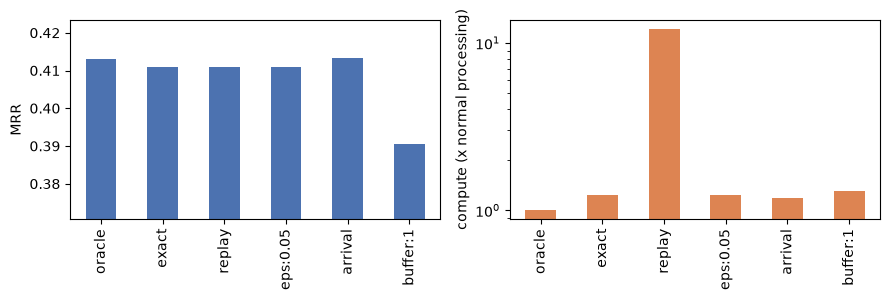

In [7]:
df = pd.DataFrame(summary["methods"]).T
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
df["mrr"].plot.bar(ax=ax[0], color="#4C72B0"); ax[0].set_ylabel("MRR"); ax[0].set_ylim(df["mrr"].min() - 0.02, df["mrr"].max() + 0.01)
df["cost_x_normal"].plot.bar(ax=ax[1], color="#DD8452", logy=True); ax[1].set_ylabel("compute (x normal processing)")
plt.tight_layout(); plt.show()

## 7. Deleting from the log is not enough
We take 150 user-item pairs that first meet in the test period. Pairs A are observed and then deleted; pairs B are
never observed. An attacker scores each pair with the model's own link logit. If the deletion really worked, A and B
look the same (AUC = 0.5).

In [8]:
from sklearn.metrics import roc_auc_score
from lategraph.stream import score_pairs
rng = np.random.default_rng(0)
seen, pairs = set(zip(S.src[:S.test0].tolist(), S.dst[:S.test0].tolist())), {}
for e in torch.cat(setup.batches[:30]).tolist():
    p = (int(S.src[e]), int(S.dst[e]))
    if p not in seen: pairs.setdefault(p, []).append(e)
keys = list(pairs); rng.shuffle(keys); A, B = keys[:150], keys[150:300]
hide = torch.tensor([e for p in B for e in pairs[p]]); D = torch.tensor([e for p in A for e in pairs[p]])
base, st0 = warm_start(model, S, setup.table)
for k in range(30):
    ev = setup.batches[k]; ev = ev[~torch.isin(ev, hide)]
    base.advance(ev); st0.insert(ev)
now = int(setup.grid.T[30])
def attack_auc(m, store):
    u = lambda P: torch.tensor([p[0] for p in P]); v = lambda P: torch.tensor([p[1] for p in P])
    sa = score_pairs(model, m, store, setup.table, u(A), v(A), now).numpy()
    sb = score_pairs(model, m, store, setup.table, u(B), v(B), now).numpy()
    return roc_auc_score(np.r_[np.ones(len(sa)), np.zeros(len(sb))], np.r_[sa, sb])
log_only = st0.clone(); log_only.remove(D)
exact = RetroactiveTGNMemory.from_trained(model.memory, setup.table).copy_state_from(base)
exact.edit(delete=D); stats = exact.repair("exact")
print("no deletion      AUC", round(attack_auc(base, st0), 3))
print("log-only delete  AUC", round(attack_auc(base, log_only), 3))
print("exact repair     AUC", round(attack_auc(exact, log_only), 3), f"(recomputed {stats.recomputed} updates)")

no deletion      AUC 0.77
log-only delete  AUC 0.572
exact repair     AUC 0.469 (recomputed 669 updates)


## 8. Does a small change fade or grow? Jacobian norms of the memory update
ε-repair is safe if every update shrinks differences: ‖∂F/∂s_own‖ + ‖∂F/∂s_partner‖ < 1. We compute the exact
Jacobians (`torch.func.jacrev` + `vmap`) on 2,000 real updates.

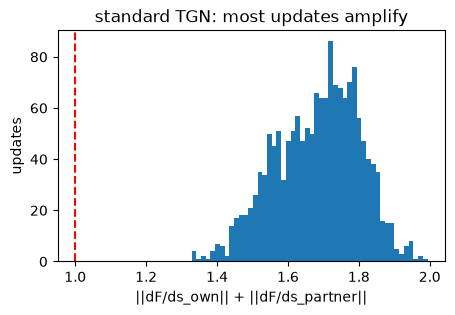

share of updates that are contractions: 0.0


In [9]:
sys.path.insert(0, os.path.join(CODE_DIR, "scripts"))
from run_contraction import jac_norms           # exact Jacobian spectral norms of the memory update
m2, _ = warm_start(model, S, setup.table)
no, npn = [], []
for k in range(10):
    ev = setup.batches[k]
    nodes, other, eid = m2.choose(ev)
    a_, b_ = jac_norms(m2, nodes, other, eid); no.append(a_.detach()); npn.append(b_.detach())
    m2.advance(ev, journal=False)
no, npn = torch.cat(no).numpy(), torch.cat(npn).numpy()
plt.figure(figsize=(5, 3)); plt.hist(no + npn, bins=50); plt.axvline(1, color="r", ls="--")
plt.xlabel("||dF/ds_own|| + ||dF/ds_partner||"); plt.ylabel("updates"); plt.title("standard TGN: most updates amplify"); plt.show()
print("share of updates that are contractions:", float(((no + npn) < 1).mean()))

## What is next
The full experiments (3 seeds, three JODIE datasets, the SEC Form 4 two-clock graph with real filing delays and
amendments, 10,000-edit exactness test, contraction-trained memories) are run with the scripts in `scripts/`; see
the README. For the final report we will add more models (DyRep, GraphMixer), larger datasets and the blog post.